# Time Series Forecasting: Market Data, Candlestick Charts, and Returns

**Target stock: MSFT** (chosen to match the group's Notebooks 3 and 4, and to satisfy the
assignment rule that NVDA may not be used as the target).

| Key | Value |
|:--|:--|
| **Course Codes** | BBT 4206 and BFS 4102 |
| **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) |
| **Semester** | September to November 2026 |
| **Lecturer** | Allan Omondi |
| **Group** | Group B6 — this notebook is Member 1's contribution |
| **Note** | Educational use only. Nothing here is investment advice. |


## What you will learn in this notebook

1. Explain the Open, High, Low, Close and Volume (OHLCV) columns and read a candlestick chart.
2. Explain why the lab uses several predictors instead of only the stock's own past price.
3. Load a market-data snapshot for **MSFT** and check it for common data problems.
4. Explain the difference between **price**, **simple return**, and **log return**, and why the
   rest of the lab forecasts returns rather than price.

**Guiding question:** using only information known at today's close, how well can tomorrow's
return be forecast — and does any extra information beat simply assuming *tomorrow equals
today*? This comparison against the naive forecast is the thread that runs through every
notebook in this lab.


## Step 1: Set Up the Notebook

In [12]:
import os
import sys
import subprocess

print("Python interpreter:", sys.executable)
print("Python version    :", sys.version.split()[0])

# Google Colab starts with an empty workspace, so we fetch the lab files first.
# This block does nothing in a local environment that already has the repo.
if "google.colab" in sys.modules and not os.path.exists("tslab"):
    subprocess.run(
        ["git", "clone", "https://github.com/course-files/TimeSeriesForecastingandNeuralNetworks.git"],
        check=True,
    )
    os.chdir("TimeSeriesForecastingandNeuralNetworks")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements/colab.txt"], check=True)
    print("Colab workspace prepared.")


Python interpreter: c:\Users\guyfl\OneDrive\Documents\SU 4.2\TSF_1\.venv\Scripts\python.exe
Python version    : 3.12.10


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf

from tslab import config
from tslab.data import load_market_data, data_quality_report

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)


## Step 2: The Target and the Predictors

**Important:** before running this notebook, `tslab/config.py` must have
`TARGET_TICKER = "MSFT"` (not `NVDA`), so that the whole group — Notebooks 1, 2, 3 and 4 —
scores the same stock. Confirm this below before going any further.


In [14]:
print("Target ticker    :", config.TARGET_TICKER)
print("Predictor tickers:", config.PREDICTOR_TICKERS)

assert config.TARGET_TICKER == "MSFT", (
    "config.TARGET_TICKER must be set to 'MSFT' in tslab/config.py "
    "to match the rest of the group's notebooks."
)


Target ticker    : MSFT
Predictor tickers: {'SP500': '^GSPC', 'TECH': 'XLK', 'VIX': '^VIX', 'US10Y': '^TNX', 'USD': 'DX-Y.NYB', 'BRENT': 'BZ=F', 'GOLD': 'GC=F'}


The seven predictors and the economic story behind each one:

| Predictor | Ticker | Why it might help forecast MSFT |
|:--|:--|:--|
| S&P 500 | ^GSPC | Broad US market — usually the single strongest predictor. |
| Tech sector ETF | XLK | MSFT's own sector; sector moves often lead individual names. |
| VIX ("fear index") | ^VIX | Expected volatility; tends to move opposite to stock prices. |
| 10-year Treasury yield | ^TNX | Rising yields can pressure technology valuations. |
| US dollar index | DX-Y.NYB | A strong dollar can pressure multinational revenue. |
| Brent crude | BZ=F | A broad macro/inflation signal. |
| Gold | GC=F | Often rises when confidence in stocks falls. |

Two rules matter here:

1. An economic story is only a **hypothesis** — the data, not the story, decides whether a
   predictor actually helps.
2. **Timing rule:** MSFT and the S&P 500 close at the same moment, so *today's* market move
   cannot forecast *today's* stock move. Only information known **up to and including today's
   close** may be used to forecast **tomorrow**.


## Step 3: Load the Data

In [15]:
data = load_market_data()
print(f"Loaded {len(data)} trading days of {config.TARGET_TICKER}, "
      f"{data.index.min().date()} to {data.index.max().date()}, "
      f"with {len(config.PREDICTOR_TICKERS)} predictor series.")

data.head()


Loaded 2981 trading days of MSFT, 2015-01-02 to 2026-11-09, with 7 predictor series.
Loaded 2981 trading days of MSFT, 2015-01-02 to 2026-11-09, with 7 predictor series.


,Open,High,Low,Close,Volume,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD
Date,,,,,,,,,,,,
2015-01-02,39.446280,40.088782,39.344834,39.530819,27913900,2058.199951,18.041685,17.790001,2.123,91.080002,56.419998,1186.000000
2015-01-05,39.201107,39.505451,39.099660,39.167294,39673900,2020.579956,17.766273,19.920000,2.039,91.379997,53.110001,1203.900024
2015-01-06,39.209570,39.522367,38.499436,38.592430,36447900,2002.609985,17.552063,21.120001,1.963,91.500000,51.099998,1219.300049
2015-01-07,38.871414,39.277205,38.457171,39.082764,29114100,2025.900024,17.700697,19.309999,1.954,91.889999,51.150002,1210.599976
2015-01-08,39.522375,40.367773,39.497014,40.232510,29645200,2062.139893,18.089773,17.010000,2.016,92.370003,50.959999,1208.400024


In [16]:
data.tail()

,Open,High,Low,Close,Volume,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD
Date,,,,,,,,,,,,
2026-11-03,508.028651,522.430823,506.840943,519.985535,20010200,7568.919922,176.509995,20.830000,4.952,101.870003,103.599998,3940.399902
2026-11-04,542.651747,558.071971,541.254422,554.728394,50807800,7688.620117,176.500000,16.610001,4.894,101.510002,94.620003,4073.000000
2026-11-05,553.870087,556.544913,531.652994,534.896729,42507900,7353.729980,162.380005,28.180000,4.837,101.550003,98.290001,4113.500000
2026-11-06,524.676478,537.292123,523.458798,529.586975,26956400,7376.859863,164.740005,25.639999,4.859,102.300003,98.320000,4074.899902
2026-11-09,543.440173,547.222905,537.661359,544.128845,25337400,7549.939941,170.880005,19.920000,4.864,101.650002,92.570000,4114.500000


## Step 4: Confirm the Loaded Data (Data Quality Checks)

Run these checks every time a new dataset is received, before modelling anything.


In [6]:
print("Number of observations and variables:", data.shape)
data.info()


Number of observations and variables: (2981, 12)
<class 'pandas.DataFrame'>
DatetimeIndex: 2981 entries, 2015-01-02 to 2026-11-09
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    2981 non-null   float64
 1   High    2981 non-null   float64
 2   Low     2981 non-null   float64
 3   Close   2981 non-null   float64
 4   Volume  2981 non-null   int64  
 5   SP500   2981 non-null   float64
 6   TECH    2981 non-null   float64
 7   VIX     2981 non-null   float64
 8   US10Y   2981 non-null   float64
 9   USD     2981 non-null   float64
 10  BRENT   2981 non-null   float64
 11  GOLD    2981 non-null   float64
dtypes: float64(11), int64(1)
memory usage: 302.8 KB


In [7]:
data.describe()

,Open,High,Low,Close,Volume,SP500,TECH,VIX,US10Y,USD,BRENT,GOLD
count,2981.000000,2981.000000,2981.000000,2981.000000,2.981000e+03,2981.000000,2981.000000,2981.000000,2981.000000,2981.000000,2981.000000,2981.000000
mean,221.434170,223.567731,219.216145,221.478039,2.865159e+07,3880.456011,65.444160,18.324566,2.778144,98.408856,68.345495,1971.998289
std,150.591992,151.955987,149.144910,150.584669,1.358873e+07,1598.001450,44.422702,6.928125,1.200831,4.714785,18.658287,962.415604
min,34.314698,34.686619,34.010355,34.154091,5.855900e+06,1829.079956,16.622932,9.140000,0.499000,88.589996,19.330000,1050.800049
25%,77.898853,78.382342,77.315118,77.898888,2.020720e+07,2579.850098,29.196531,13.760000,1.814000,95.059998,55.049999,1278.599976
50%,206.032783,207.972075,203.615372,206.187607,2.546580e+07,3626.909912,58.637932,16.639999,2.508000,97.870003,67.419998,1752.000000
75%,358.098631,362.736982,352.126500,354.979095,3.305460e+07,4697.959961,89.693329,21.030001,4.033000,101.610001,79.779999,2021.599976
max,553.870087,558.071971,542.012959,554.728394,1.862016e+08,7818.930176,202.000000,82.690002,5.311000,114.110001,127.980003,5318.399902


In [8]:
# tslab's own data-quality helper (missing values, duplicate dates, zero/negative
# prices, and other common problems in financial data).
data_quality_report(data)


rows                               2981
first_date                   2015-01-02
last_date                    2026-11-09
duplicate_dates                       0
missing_values                        0
non_positive_prices                   0
days_with_zero_volume                 0
high_below_low                        0
longest_gap_in_days                   4
days_with_move_over_10pct             6
dtype: object

## Step 5: Candlestick Chart

Each candle shows one trading day: the body spans **open-to-close** (colour shows whether the
day closed up or down), and the thin wicks above/below mark the day's **high** and **low**.
Volume is shown as a bar panel beneath the price.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


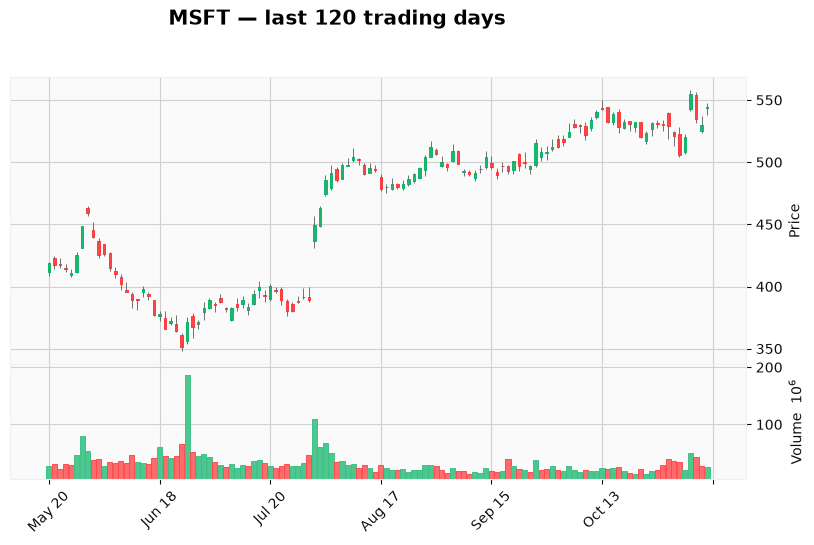

In [9]:
recent = data.tail(120)  # last ~6 months of trading days, for readability

mpf.plot(
    recent[["Open", "High", "Low", "Close", "Volume"]],
    type="candle",
    volume=True,
    style="yahoo",
    title=f"{config.TARGET_TICKER} — last {len(recent)} trading days",
    figratio=(16, 9),
)


## Step 6: Price, Simple Return, and Log Return

- **Simple return:** `(P_t - P_{t-1}) / P_{t-1}` — the plain percentage change.
- **Log return:** `ln(P_t / P_{t-1})` — approximately equal to the simple return for small moves,
  but **additive across time** (the sum of daily log returns equals the log return over the whole
  period) and more symmetric for gains vs losses. This is why the rest of the lab forecasts
  **log returns**, not price.


In [10]:
price = data["Close"]
simple_return = price.pct_change()
log_return = np.log(price / price.shift(1))

returns = pd.DataFrame({"simple_return": simple_return, "log_return": log_return}).dropna()
returns.describe()


,simple_return,log_return
count,2980.000000,2980.000000
mean,0.001031,0.000880
std,0.017398,0.017358
min,-0.147390,-0.159453
25%,-0.007086,-0.007111
50%,0.000908,0.000907
75%,0.009660,0.009614
max,0.155067,0.144159


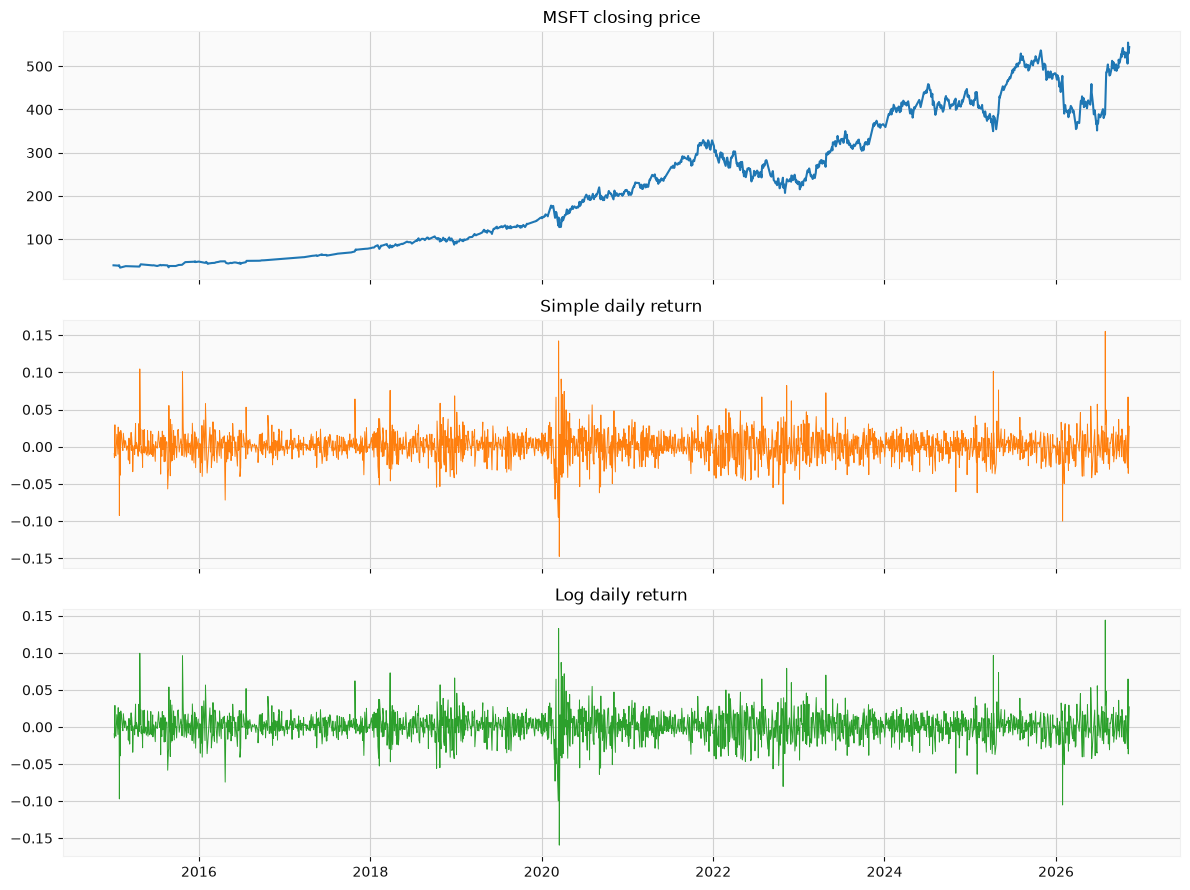

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(price.index, price, color="tab:blue")
axes[0].set_title(f"{config.TARGET_TICKER} closing price")

axes[1].plot(simple_return.index, simple_return, color="tab:orange", linewidth=0.7)
axes[1].set_title("Simple daily return")

axes[2].plot(log_return.index, log_return, color="tab:green", linewidth=0.7)
axes[2].set_title("Log daily return")

plt.tight_layout()
plt.show()


Notice the shape of each plot: the **price** panel drifts upward with no fixed level to
return to (a random walk — this is examined formally in Notebook 2), while the two **return**
panels hover around zero with a roughly constant spread throughout. That visual contrast is
exactly the stationarity argument Notebook 2 tests statistically with ADF and KPSS.


## Step 7: Summary and Reflection

- MSFT's price series looks like a random walk: no fixed mean, a level that drifts over time.
- Both return series oscillate around zero with a roughly stable spread — the visual signature
  of a stationary series.
- This is why the lab forecasts **returns**, not price: a forecasting model needs a target whose
  statistical behaviour does not change arbitrarily over time.
- **Next notebook (Notebook 2):** confirm this stationarity argument formally with ADF/KPSS
  tests, rolling statistics, ACF/PACF, a spurious-regression demonstration, and GARCH volatility
  clustering.
